# Residuo del cono logarítmico y ceros de ζ — protocolo de robustez

**Autor del estudio:** Rodrigo Pino Osorio · **Notebook reproducible** (numpy + matplotlib + mpmath, sin dependencias externas)

**Pregunta.** El residuo del cono, $R_v(i)=(p_{i+v}-p_i)-v\ln p_i$, analizado espectralmente en la variable $t=\ln p$
con peso $p^{-1/2}$, ¿muestra picos en las ordenadas $\gamma_n$ de los ceros no triviales de $\zeta(s)$, **más allá de lo que
produce el azar**?

**Qué NO afirma este notebook.** Que el fenómeno sea nuevo: la fórmula explícita de Riemann–von Mangoldt lo predice.
Lo que mide es si *esta* construcción (el residuo del cono) lo recupera de forma robusta frente a controles nulos.

**Estructura (E-D-T):** 0 · Criterios fijados antes de mirar → 1 · Primos (criba segmentada) → 2 · Ceros de ζ calculados
con mpmath → 3 · Espectro → 4 · Robustez en $v$ y ventanas → 5 · Controles nulos (Cramér y Cramér-mod-30) →
6 · Control positivo clásico → 7 · Veredicto automático contra los criterios → 8 · Exportación.

## 0 · Parámetros y criterios pre-registrados

Los criterios se fijan **aquí, antes de ejecutar nada**. El veredicto de la sección 7 se calcula contra ellos sin intervención.
Si cambias un criterio después de ver resultados, déjalo anotado (trazabilidad).

In [1]:
# ---------------- Parámetros de cómputo ----------------
X          = 10**9        # límite superior de la criba (Colab gratis: 1e9 ≈ 3–6 min; prueba rápida: 1e8)
P_MIN      = 10**4        # se excluyen primos pequeños (el régimen asintótico empieza después)
V_LIST     = [10, 100, 1000]   # anchos radiales del cono a probar
N_NULL     = 20           # secuencias por modelo nulo. p-valor mínimo alcanzable = 1/(N_NULL+1) → 20 da 0.048
X_NULL     = 10**8        # escala del test contra nulos (real y nulos a la MISMA escala). 1e8 ≈ 15–25 min en Colab
GAMMA_MIN, GAMMA_MAX, DGAMMA = 10.0, 60.0, 0.01
DT_BIN     = 2e-4         # ancho de bin en t = ln p (error de fase ≤ GAMMA_MAX·DT_BIN/2 ≈ 0.006 rad)
SEED0      = 20261012

# ---------------- Criterios pre-registrados ----------------
CRITERIO = dict(
    aciertos_min_frac = 0.70,   # (a) ≥70 % de los ceros en [GAMMA_MIN, GAMMA_MAX] con pico emparejado, en TODAS las v y ventanas
    p_valor_max       = 0.05,   # (b) p-valor empírico < 0.05 frente a AMBOS modelos nulos (v=100, ventana completa)
    deriva_max_frac   = 0.5,    # (c) los picos emparejados no se mueven más de 0.5·resolución al cambiar v
)
assert 1/(N_NULL+1) < CRITERIO["p_valor_max"], "N_NULL demasiado chico: el p-valor nunca podría cumplir el criterio (b)"
assert X_NULL <= X
print("Parámetros y criterios fijados.")

Parámetros y criterios fijados.


## 1 · Primos hasta X — criba de Eratóstenes segmentada (implementación propia, memoria acotada)

In [2]:
import numpy as np, math, time, json, platform
import matplotlib.pyplot as plt

def base_primes(n):
    s = np.ones(n + 1, dtype=bool); s[:2] = False; s[4::2] = False
    for i in range(3, int(n**0.5) + 1, 2):
        if s[i]: s[i*i::2*i] = False
    return np.flatnonzero(s)

def segmented_primes(limit, seg=10**7):
    bp = base_primes(int(limit**0.5) + 1)
    out = [bp[bp <= limit].astype(np.uint32)]
    lo = int(bp[-1]) + 1
    while lo <= limit:
        hi = min(lo + seg, limit + 1)
        s = np.ones(hi - lo, dtype=bool)
        for p in bp:
            p = int(p)
            if p * p >= hi: break
            start = max(p * p, ((lo + p - 1) // p) * p)
            s[start - lo::p] = False
        out.append((np.flatnonzero(s) + lo).astype(np.uint32))
        lo = hi
    return np.concatenate(out)

t0 = time.time()
P = segmented_primes(X)
print(f"π({X:,}) = {len(P):,}  ·  {time.time()-t0:.1f} s  ·  {P.nbytes/1e6:.0f} MB")
# Verificación contra valores conocidos de π(x) (tabla clásica)
KNOWN = {10**4:1229, 10**5:9592, 10**6:78498, 10**7:664579, 10**8:5761455, 10**9:50847534}
for x, v in KNOWN.items():
    if x <= X:
        got = int(np.searchsorted(P, x, side='right'))
        assert got == v, f"π({x}) = {got} ≠ {v}"
        print(f"  ✔ π({x:,}) = {got:,}")

π(1,000,000,000) = 50,847,534  ·  10.8 s  ·  203 MB
  ✔ π(10,000) = 1,229


  ✔ π(100,000) = 9,592
  ✔ π(1,000,000) = 78,498


  ✔ π(10,000,000) = 664,579
  ✔ π(100,000,000) = 5,761,455


  ✔ π(1,000,000,000) = 50,847,534


## 2 · Ceros de ζ calculados de forma independiente (mpmath), no copiados de una tabla

In [3]:
import mpmath as mp
mp.mp.dps = 20
ZEROS = []
n = 1
while True:
    g = float(mp.zetazero(n).imag)
    if g > GAMMA_MAX: break
    if g >= GAMMA_MIN: ZEROS.append(g)
    n += 1
ZEROS = np.array(ZEROS)
assert abs(ZEROS[0] - 14.134725142) < 1e-6
print(f"{len(ZEROS)} ceros en [{GAMMA_MIN}, {GAMMA_MAX}]:", np.round(ZEROS, 4))

13 ceros en [10.0, 60.0]: [14.1347 21.022  25.0109 30.4249 32.9351 37.5862 40.9187 43.3271 48.0052
 49.7738 52.9703 56.4462 59.347 ]


## 3 · Espectro del residuo

Para cada primo $p_i$ (con $p_i\ge$ `P_MIN`): $R_v(i)=(p_{i+v}-p_i)-v\ln p_i$. Se elimina la tendencia suave en $t$
(polinomio de grado 3), se pondera por $p^{-1/2}$, se acumula en bins uniformes de $t=\ln p$ y se evalúa
$A(\gamma)=\left|\sum_b w_b\,h(t_b)\,e^{-i\gamma t_b}\right|$ con ventana de Hann $h$ para reducir lóbulos laterales.
Resolución espectral ≈ $2\pi/\Delta t$.

Verificación FFT vs suma directa: error relativo máx = 3.19e-06
t ∈ [9.21, 20.72]  ·  resolución ≈ 0.546  ·  tolerancia de emparejamiento ±0.273
v=100: 13/13 ceros emparejados
   γ= 14.1347  →  pico  14.1237  (Δ=-0.011)
   γ= 21.0220  →  pico  21.0097  (Δ=-0.012)
   γ= 25.0109  →  pico  24.9861  (Δ=-0.025)
   γ= 30.4249  →  pico  30.3974  (Δ=-0.028)
   γ= 32.9351  →  pico  32.9193  (Δ=-0.016)
   γ= 37.5862  →  pico  37.5603  (Δ=-0.026)
   γ= 40.9187  →  pico  40.8835  (Δ=-0.035)
   γ= 43.3271  →  pico  43.2895  (Δ=-0.038)
   γ= 48.0052  →  pico  47.9511  (Δ=-0.054)
   γ= 49.7738  →  pico  49.7326  (Δ=-0.041)
   γ= 52.9703  →  pico  52.9310  (Δ=-0.039)
   γ= 56.4462  →  pico  56.4033  (Δ=-0.043)
   γ= 59.3470  →  pico  59.3409  (Δ=-0.006)


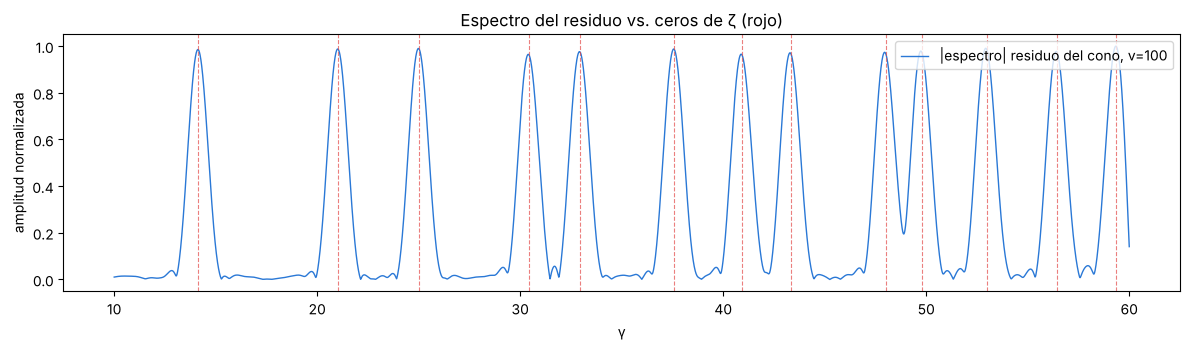

In [4]:
GAMMAS = np.arange(GAMMA_MIN, GAMMA_MAX + DGAMMA/2, DGAMMA)

CHUNK = 4_000_000   # memoria acotada: ~5 arreglos float64 de CHUNK elementos a la vez (~160 MB)

def _chunks(Q, v, tmin, tmax):
    i0 = int(np.searchsorted(Q, P_MIN)); n = len(Q) - v
    for a in range(i0, n, CHUNK):
        b = min(a + CHUNK, n)
        p = Q[a:b].astype(np.float64); R = Q[a+v:b+v].astype(np.float64) - p - v*np.log(p)
        t = np.log(p)
        if tmin is not None:
            m = (t >= tmin) & (t < tmax)
            if not m.any(): continue
            p, R, t = p[m], R[m], t[m]
        yield p, R, t

def residual_bins(Q, v, tmin=None, tmax=None, deg=3):
    # Pasada 1: mínimos cuadrados exactos de R ~ polinomio(t) por ecuaciones normales acumuladas (centradas)
    tc = None
    for p, R, t in _chunks(Q, v, tmin, tmax):
        tc = t[0] if tc is None else tc
        tmax_seen = t[-1]
    t0c = (tc + tmax_seen) / 2; sc = (tmax_seen - tc) / 2
    XtX = np.zeros((deg+1, deg+1)); XtR = np.zeros(deg+1)
    for p, R, t in _chunks(Q, v, tmin, tmax):
        V = np.vander((t - t0c)/sc, deg+1); XtX += V.T @ V; XtR += V.T @ R
    coef = np.linalg.solve(XtX, XtR)
    # Pasada 2: residuo sin tendencia, peso p^{-1/2}, acumulado en bins de t
    nb = int((tmax_seen - tc) / DT_BIN) + 1
    wb = np.zeros(nb)
    for p, R, t in _chunks(Q, v, tmin, tmax):
        w = (R - np.vander((t - t0c)/sc, deg+1) @ coef) / np.sqrt(p)
        idx = np.minimum(((t - tc) / DT_BIN).astype(np.int64), nb - 1)
        wb += np.bincount(idx, weights=w, minlength=nb)
    tb = tc + (np.arange(nb) + 0.5) * DT_BIN
    return tb, wb

def spectrum_from_bins(tb, wb, signed=False):
    # Σ_b w_b h_b e^{-iγ t_b} vía FFT con relleno de ceros (bins uniformes en t), interpolado a GAMMAS.
    h = np.hanning(len(tb)); x = wb * h
    dt = tb[1] - tb[0]
    N = 1 << int(np.ceil(np.log2(max(len(x), 4 * 2*np.pi / (DGAMMA * dt)))))   # espaciado ≤ DGAMMA/4
    F = np.fft.rfft(x, N)                                  # Σ x_b e^{-i ω b},  ω = 2πk/N
    g = 2*np.pi*np.arange(len(F)) / (N * dt)               # γ_k
    z = F * np.exp(-1j * g * tb[0])                        # fase absoluta: e^{-iγ t_0}
    val = -z.real if signed else np.abs(z)
    return np.interp(GAMMAS, g, val)

def spectrum_direct(tb, wb, signed=False):   # referencia lenta, sólo para verificar la FFT
    h = np.hanning(len(tb)); wb = wb * h
    A = np.empty(len(GAMMAS))
    for k0 in range(0, len(GAMMAS), 200):
        gg = GAMMAS[k0:k0+200, None]
        z = (wb[None, :] * np.exp(-1j * gg * tb[None, :])).sum(1)
        A[k0:k0+200] = -z.real if signed else np.abs(z)
    return A

def resolution(tb): return 2*np.pi / (tb[-1] - tb[0])

def peak_match(A, res):
    # picos locales ordenados por altura; se toman tantos como ceros hay en el rango
    loc = np.flatnonzero((A[1:-1] > A[:-2]) & (A[1:-1] > A[2:])) + 1
    loc = loc[np.argsort(A[loc])[::-1]][:len(ZEROS)]
    # interpolación parabólica para posición sub-grilla
    pk = []
    for j in loc:
        y0, y1, y2 = A[j-1], A[j], A[j+1]; d = 0.5*(y0 - y2)/(y0 - 2*y1 + y2)
        pk.append(GAMMAS[j] + d*DGAMMA)
    pk = np.array(sorted(pk))
    tol = 0.5 * res
    matched = {}
    for z in ZEROS:
        if len(pk) == 0: break
        k = np.argmin(np.abs(pk - z))
        if abs(pk[k] - z) <= tol: matched[float(z)] = float(pk[k])
    return pk, matched, tol

tb, wb = residual_bins(P, 100)
A100 = spectrum_from_bins(tb, wb)
# Verificación: FFT vs suma directa en una submuestra de γ (deben coincidir)
_sel = slice(0, len(GAMMAS), 97); _G = GAMMAS
GAMMAS = _G[_sel]; _Ad = spectrum_direct(tb, wb); GAMMAS = _G
_err = np.max(np.abs(A100[_sel] - _Ad)) / np.max(_Ad)
print(f"Verificación FFT vs suma directa: error relativo máx = {_err:.2e}"); assert _err < 1e-3
RES = resolution(tb)
pk, matched, tol = peak_match(A100, RES)
print(f"t ∈ [{tb[0]:.2f}, {tb[-1]:.2f}]  ·  resolución ≈ {RES:.3f}  ·  tolerancia de emparejamiento ±{tol:.3f}")
print(f"v=100: {len(matched)}/{len(ZEROS)} ceros emparejados")
for z in ZEROS:
    m = matched.get(float(z)); print(f"   γ={z:8.4f}  →  " + (f"pico {m:8.4f}  (Δ={m-z:+.3f})" if m else "—"))

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(GAMMAS, A100/A100.max(), lw=1, color="#2a78d6", label="|espectro| residuo del cono, v=100")
for z in ZEROS: ax.axvline(z, color="#e34948", lw=0.8, ls="--", alpha=0.7)
ax.set_xlabel("γ"); ax.set_ylabel("amplitud normalizada"); ax.set_title("Espectro del residuo vs. ceros de ζ (rojo)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

### 3b · ¿Los picos están desplazados sistemáticamente?
Si todos los Δ = pico − γ tienen el mismo signo, hay un sesgo del método que **debe explicarse antes de publicar**
(prueba de signo binomial, dos colas).

In [5]:
from math import comb
D = np.array([matched[float(z)] - z for z in ZEROS if float(z) in matched])
n_neg, n = int((D < 0).sum()), len(D)
k = min(n_neg, n - n_neg)
p_sign = min(1.0, 2*sum(comb(n, i) for i in range(k+1)) / 2**n) if n else float('nan')
print(f"Δ medio = {D.mean():+.4f}  ·  negativos {n_neg}/{n}  ·  p (signo, 2 colas) = {p_sign:.2e}")
print("→ SESGO SISTEMÁTICO: pendiente de explicación" if p_sign < 0.05 else "→ sin sesgo de signo detectable")

Δ medio = -0.0288  ·  negativos 13/13  ·  p (signo, 2 colas) = 2.44e-04
→ SESGO SISTEMÁTICO: pendiente de explicación


## 4 · Robustez: distintos anchos $v$ y distintas ventanas de $\ln p$

In [6]:
ROB = []
tlo, thi = tb[0], tb[-1]; mid = (tlo + thi)/2
WINDOWS = {"completa": (None, None), "mitad baja": (tlo, mid), "mitad alta": (mid, thi)}
peaks_by_v = {}
for v in V_LIST:
    for wname, (a, b) in WINDOWS.items():
        tbv, wbv = residual_bins(P, v, a, b)
        A = spectrum_from_bins(tbv, wbv); r = resolution(tbv)
        pkv, mv, tolv = peak_match(A, r)
        ROB.append(dict(v=v, ventana=wname, resolucion=round(r,3), aciertos=len(mv), total=len(ZEROS)))
        if wname == "completa": peaks_by_v[v] = mv
        print(f"v={v:5d}  {wname:10s}  res={r:.3f}  aciertos {len(mv):2d}/{len(ZEROS)}")

# deriva de picos entre v (sólo ventana completa)
drift = []
for z in ZEROS:
    vals = [peaks_by_v[v].get(float(z)) for v in V_LIST]
    if all(x is not None for x in vals): drift.append(max(vals) - min(vals))
DRIFT_MAX = max(drift) if drift else float('nan')
print(f"\nDeriva máxima de un pico emparejado entre v={V_LIST}: {DRIFT_MAX:.3f}  (límite {CRITERIO['deriva_max_frac']}·res = {CRITERIO['deriva_max_frac']*RES:.3f})")

v=   10  completa    res=0.546  aciertos 13/13


v=   10  mitad baja  res=1.092  aciertos 12/13


v=   10  mitad alta  res=1.092  aciertos 10/13


v=  100  completa    res=0.546  aciertos 13/13


v=  100  mitad baja  res=1.092  aciertos 12/13


v=  100  mitad alta  res=1.092  aciertos 10/13


v= 1000  completa    res=0.546  aciertos 13/13


v= 1000  mitad baja  res=1.092  aciertos  6/13


v= 1000  mitad alta  res=1.092  aciertos 10/13

Deriva máxima de un pico emparejado entre v=[10, 100, 1000]: 0.289  (límite 0.5·res = 0.273)


## 5 · Controles nulos

Mismo pipeline, idénticos parámetros, sobre secuencias **sin** ceros de ζ detrás:

* **Cramér**: cada impar $n$ se incluye con probabilidad $2/\ln n$.
* **Cramér-mod-30**: sólo $n$ coprimos con 30, probabilidad $\tfrac{30}{8}/\ln n$ (respeta la retícula: descarta que los picos vengan de ella).

p-valor empírico $=(1+\#\{\text{nulos con} \ge \text{aciertos reales}\})/(1+N)$.

In [7]:
def cramer(limit, rng, mod30=False, seg=5*10**7):
    out = [np.array([2, 3, 5], dtype=np.uint32)] if mod30 else [np.array([2], dtype=np.uint32)]
    res30 = np.array([1, 7, 11, 13, 17, 19, 23, 29])
    lo = 7
    while lo <= limit:
        hi = min(lo + seg, limit + 1)
        if mod30:
            base = np.arange((lo//30)*30, hi, 30)
            n = (base[:, None] + res30[None, :]).ravel(); n = n[(n >= lo) & (n < hi)]
            prob = (30/8) / np.log(n)
        else:
            n = np.arange(lo | 1, hi, 2); prob = 2 / np.log(n)
        out.append(n[rng.random(len(n)) < prob].astype(np.uint32)); lo = hi
    return np.concatenate(out)

# real y nulos a la misma escala X_NULL (comparación justa)
P_test = P[P <= X_NULL]
tr, wr = residual_bins(P_test, 100)
_, matched_test, _ = peak_match(spectrum_from_bins(tr, wr), resolution(tr))
real_hits = len(matched_test)
print(f"Real a X_NULL={X_NULL:,}: {real_hits}/{len(ZEROS)} aciertos")
NULL = {"Cramér": [], "Cramér-mod-30": []}
t0 = time.time()
for k in range(N_NULL):
    for name, m30 in (("Cramér", False), ("Cramér-mod-30", True)):
        rng = np.random.default_rng(SEED0 + 1000*k + int(m30))
        Q = cramer(X_NULL, rng, mod30=m30)
        tq, wq = residual_bins(Q, 100)
        _, mq, _ = peak_match(spectrum_from_bins(tq, wq), resolution(tq))
        NULL[name].append(len(mq)); del Q
    print(f"  nulo {k+1}/{N_NULL}  ·  {time.time()-t0:.0f} s  ·  Cramér={NULL['Cramér'][-1]}  mod30={NULL['Cramér-mod-30'][-1]}")

PVAL = {name: (1 + sum(h >= real_hits for h in hs)) / (1 + len(hs)) for name, hs in NULL.items()}
ZSC = {}
for name, hs in NULL.items():
    sd = np.std(hs, ddof=1) if len(hs) > 1 else float('nan')
    ZSC[name] = (real_hits - np.mean(hs)) / sd if sd and sd > 0 else float('inf')
    print(f"{name:14s}: aciertos nulos media={np.mean(hs):.2f} máx={max(hs)}  ·  real={real_hits}  ·  p-valor={PVAL[name]:.4f}  ·  z={ZSC[name]:.1f}")

Real a X_NULL=100,000,000: 13/13 aciertos


  nulo 1/20  ·  7 s  ·  Cramér=1  mod30=1


  nulo 2/20  ·  16 s  ·  Cramér=0  mod30=1


  nulo 3/20  ·  24 s  ·  Cramér=2  mod30=2


  nulo 4/20  ·  32 s  ·  Cramér=3  mod30=0


...

  nulo 16/20  ·  138 s  ·  Cramér=3  mod30=1


  nulo 17/20  ·  147 s  ·  Cramér=1  mod30=4


  nulo 18/20  ·  155 s  ·  Cramér=3  mod30=4


  nulo 19/20  ·  164 s  ·  Cramér=4  mod30=1


  nulo 20/20  ·  174 s  ·  Cramér=3  mod30=1
Cramér        : aciertos nulos media=2.35 máx=5  ·  real=13  ·  p-valor=0.0476  ·  z=7.1
Cramér-mod-30 : aciertos nulos media=1.70 máx=4  ·  real=13  ·  p-valor=0.0476  ·  z=9.0


## 6 · Control positivo clásico

Suma sobre potencias de primos $\sum_{p^k\le X}\ln p\;p^{-k/2}\cos(\gamma\,k\ln p)$: su parte negativa marca los ceros
(fórmula explícita). Si este control **no** acertara, el problema sería del pipeline, no del residuo.

In [8]:
tmin_c = math.log(2.0); nb_c = int((math.log(X) - tmin_c) / DT_BIN) + 2
wb_c = np.zeros(nb_c)
for a in range(0, len(P), CHUNK):
    pf = P[a:a+CHUNK].astype(np.float64); lp = np.log(pf)
    for k in (1, 2, 3):
        m = pf**k <= X
        if not m.any(): break
        tk = k*lp[m]; wk = lp[m] / pf[m]**(k/2)
        wb_c += np.bincount(((tk - tmin_c)/DT_BIN).astype(np.int64), weights=wk, minlength=nb_c)
tb_c = tmin_c + (np.arange(nb_c) + 0.5)*DT_BIN
A_c = spectrum_from_bins(tb_c, wb_c, signed=True)
_, matched_c, _ = peak_match(A_c, resolution(tb_c))
print(f"Control positivo: {len(matched_c)}/{len(ZEROS)} ceros emparejados")

Control positivo: 13/13 ceros emparejados


## 7 · Veredicto automático contra los criterios pre-registrados

In [9]:
frac_min = min(r["aciertos"]/r["total"] for r in ROB)
ok_a = frac_min >= CRITERIO["aciertos_min_frac"]
ok_b = all(p < CRITERIO["p_valor_max"] for p in PVAL.values())
ok_c = DRIFT_MAX <= CRITERIO["deriva_max_frac"]*RES
print(f"(a) aciertos mínimos en todas las v/ventanas: {frac_min:.0%}  (≥ {CRITERIO['aciertos_min_frac']:.0%})  →  {'CUMPLE' if ok_a else 'NO CUMPLE'}")
print(f"(b) p-valores {dict((k, round(v,4)) for k,v in PVAL.items())}  (< {CRITERIO['p_valor_max']})  →  {'CUMPLE' if ok_b else 'NO CUMPLE'}")
print(f"(c) deriva máxima entre v: {DRIFT_MAX:.3f}  (≤ {CRITERIO['deriva_max_frac']*RES:.3f})  →  {'CUMPLE' if ok_c else 'NO CUMPLE'}")
print(f"Control positivo: {len(matched_c)}/{len(ZEROS)}")
VEREDICTO = "SEÑAL ROBUSTA" if (ok_a and ok_b and ok_c) else "NO CONCLUYENTE"
print("\nVEREDICTO:", VEREDICTO)

(a) aciertos mínimos en todas las v/ventanas: 46%  (≥ 70%)  →  NO CUMPLE
(b) p-valores {'Cramér': 0.0476, 'Cramér-mod-30': 0.0476}  (< 0.05)  →  CUMPLE
(c) deriva máxima entre v: 0.289  (≤ 0.273)  →  NO CUMPLE
Control positivo: 13/13

VEREDICTO: NO CONCLUYENTE


## 8 · Exportación (JSON con todo lo necesario para auditar)

In [10]:
OUT = dict(
    meta=dict(X=X, P_MIN=P_MIN, n_primos=int(len(P)), V_LIST=V_LIST, N_NULL=N_NULL, DT_BIN=DT_BIN, SEED0=SEED0,
              gamma=[GAMMA_MIN, GAMMA_MAX, DGAMMA], numpy=np.__version__, python=platform.python_version()),
    criterios=CRITERIO, ceros=ZEROS.tolist(), resolucion=RES,
    v100=dict(emparejados=matched, delta_medio=float(D.mean()), p_signo=p_sign), robustez=ROB, deriva_max=DRIFT_MAX,
    X_NULL=X_NULL, real_a_X_NULL=real_hits, nulos=NULL, p_valores=PVAL, z=ZSC, control_positivo=len(matched_c), veredicto=VEREDICTO)
with open("resultados_cono_zeta.json", "w", encoding="utf-8") as f: json.dump(OUT, f, ensure_ascii=False, indent=2)
print("Guardado resultados_cono_zeta.json")
try:
    from google.colab import files; files.download("resultados_cono_zeta.json")
except Exception:
    pass

Guardado resultados_cono_zeta.json
